# Test

In [12]:
import rebound
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
sim = rebound.Simulation()
sim.integrator = "whfast"
sim.units = ("AU", "yr", "Msun")

In [4]:
sim.add(m=1.0, r=0.00465047)
# (a semieje mayor), (e excentricidad)
sim.add(m=1e-3, a=5.2, e=0, r=0.000477895)
sim.move_to_com()
sim.dt=sim.particles[1].P/20

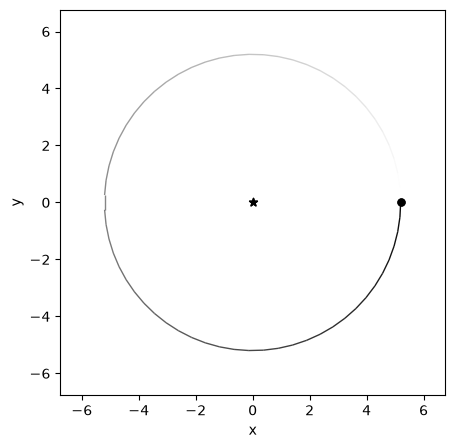

In [5]:
%matplotlib inline
op = rebound.OrbitPlot(sim)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


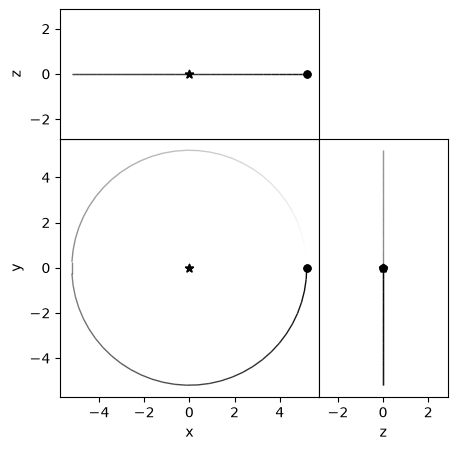

In [6]:
ops = rebound.OrbitPlotSet(sim)

In [7]:
sim.status(showAllFields=False)

---------------------------------
REBOUND version:     	5.2.2
REBOUND built on:    	Oct  5 2026 13:03:15
Number of particles: 	2
Selected integrator: 	whfast
Simulation time:     	0.0000000000000000e+00
Current timestep:    	0.592606
---------------------------------
<rebound.particle.Particle object at 0x7f65ca9c5740, m=1.0 x=-0.005194805194805196 y=0.0 z=0.0 vx=0.0 vy=-0.0027539303707624497 vz=0.0>
<rebound.particle.Particle object at 0x7f65ca9c5640, m=0.001 x=5.194805194805195 y=0.0 z=0.0 vx=0.0 vy=2.753930370762449 vz=0.0>
---------------------------------


In [8]:
sim.integrate(0.0)
sim.widget(size=(950,950))


REBOUND Webserver listening on http://localhost:1234 (not secure) ...


In [9]:
Num = 100000
times = np.linspace(0., 1000000., Num)
a1 = []
e1 = []
t1 = []

E0 = sim.energy()
Lx0, Ly0, Lz0 = sim.angular_momentum()
L0 = np.sqrt(Lx0**2 + Ly0**2 + Lz0**2)

err_ener=[]
err_ang=[]

for i, t in enumerate(times):
    sim.integrate(t, exact_finish_time=0)
    a1.append(sim.particles[1].a)
    e1.append(sim.particles[1].e)
    t1.append(sim.t)

    E_actual = sim.energy()
    err_ener.append(abs((E_actual - E0) / E0))

    Lx, Ly, Lz = sim.angular_momentum()
    L_actual = np.sqrt(Lx**2 + Ly**2 + Lz**2)
    err_ang.append(abs((L_actual - L0) / L0))

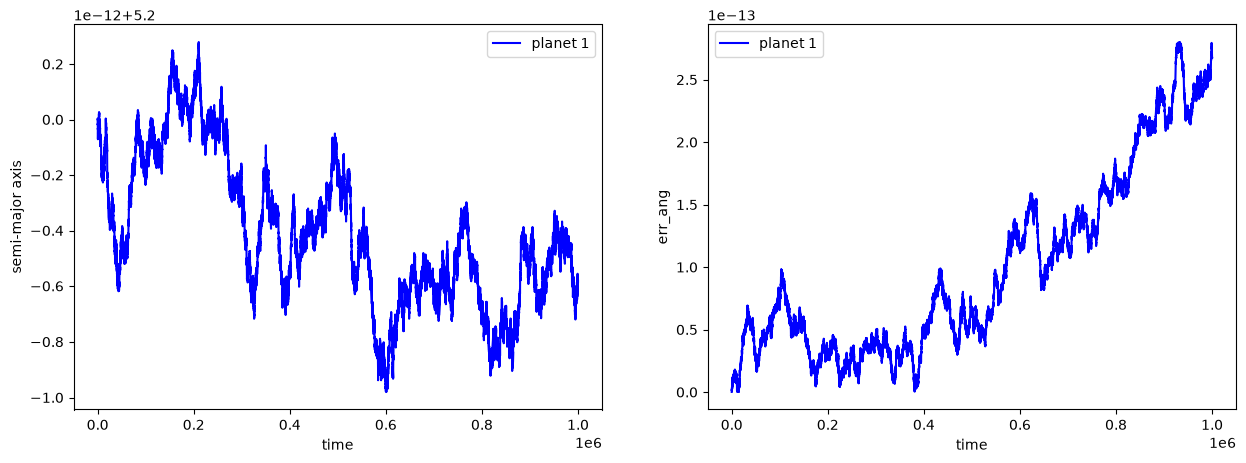

In [10]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time")
ax.set_ylabel("semi-major axis")
plt.plot(t1, a1, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time")
ax.set_ylabel("eccentrecity")
ax.set_ylabel("err_ang")
plt.plot(t1, e1, color="blue", label="planet 1")
ax.legend(loc="best")

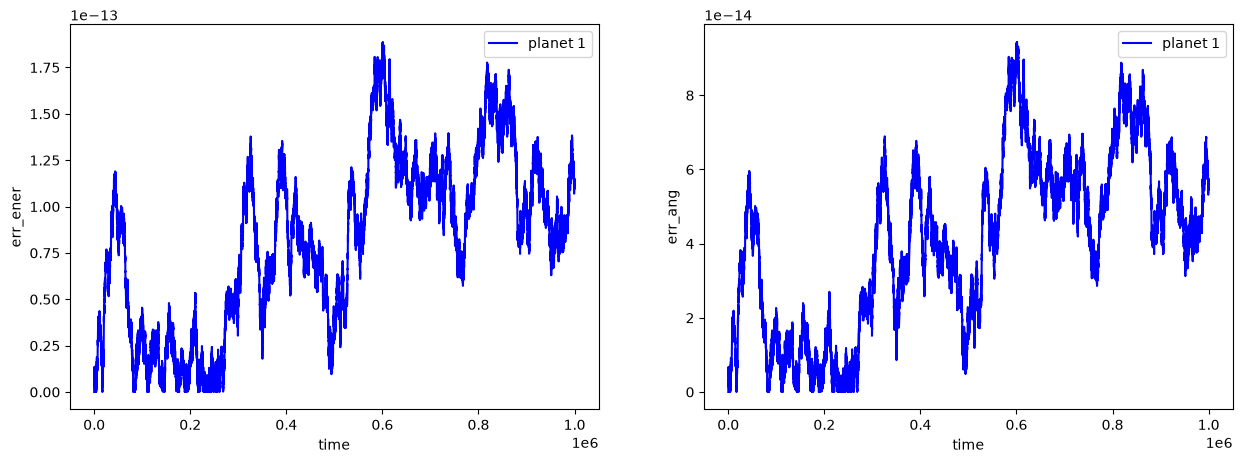

In [11]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time")
#ax.set_ylabel("semi-major axis")
ax.set_ylabel("err_ener")
# plt.plot(t1, a1, color="blue", label="planet 1")
plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time")
#ax.set_ylabel("eccentrecity")
ax.set_ylabel("err_ang")
# plt.plot(t1, e1, color="blue", label="planet 1")
plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")